# Explore OSL errors with Monte Carlo uncertainty analysis

We want to inspect how large the errors of OSL really are.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fitting_engine import FittingEngine

engine = FittingEngine(verbose=True)

First, we set our constants.

In [2]:
# slicing properties
n_points = 30
y_err_std = 0.05
x_length = 3

# material properties
order = 0.0
sigma_phi = 5
mu = 5

# sample parameters
t_exposure_1 = 1_000

Next, we make a function that creates random luminescence data using the given parameters.

In [3]:
def generate_luminescence_data(n_points, y_err_std, x_legnth, order, sigma_phi,
    mu, t_exposure_1):

    x_data = np.linspace(0, x_length, n_points)
    y_data = engine.models.expo(x_data, order, sigma_phi, mu, t_exposure_1)

    # add random perturbation
    perturbation = np.random.normal(loc=0.0, scale=y_err_std, size=n_points)
    y_data += perturbation

    return x_data, y_data

Now we can simulate thousands of independent runs with the same parameters. This is equivalent to one scientist performing the same experiment in different parallel worlds and thus obtaining different results because of the random noise. The accuracy of the method is determined by how large the influence of the random noise really is. The name of this method is Monte Carlo parameter uncertainty analysis.

In [4]:
n_fits = 100_000

t_exposure_1_fits = []

for _ in range(n_fits):
    x_data, y_data = generate_luminescence_data(n_points, y_err_std, x_length,
        order, sigma_phi, mu, t_exposure_1)

    known_params = {
        "order": order,
        "sigma_phi": sigma_phi,
        "mu": mu     
    }

    # We assume a perfect initial guess. Because the problem is one-dimensional
    # it is no large simplification.
    initial_guess = {"t_exposure_1": t_exposure_1}

    fit_result = engine.easy_fit(x_data, y_data, engine.models.expo,
        known_params, initial_guess, y_err_std=y_err_std,
        only_positive=True)

    t_exposure_1_fits.append(fit_result.best_fit["t_exposure_1"])

Now we plot the results of each experiments performed in a parallel reality in a histogram. This shows the unerlying error of obtaining the exposure time through a fit.

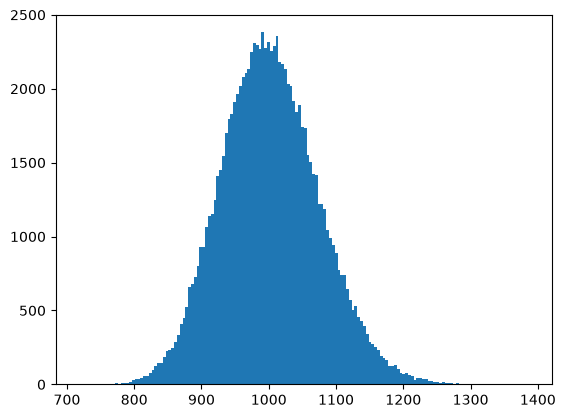

In [5]:
plt.hist(t_exposure_1_fits, bins="fd")
plt.show()

To obtain a measure for the uncertainty, e.g. width of this histogram distribution, we use half the 68% quantile width. For a normal distribution this is equivalent to 1 standard deviation.

In [6]:
u_68 = (np.quantile(t_exposure_1_fits, 0.841345) \
    - np.quantile(t_exposure_1_fits, 0.158655)) / 2
print(u_68)

72.25992849334835


Now we can study the influence of parameters like `y_err_std` on this width and thus the uncertainty of our exposure time fit. To do this, we combine everything into one compact function.

In [7]:
def get_u_68(n_fits, n_points, y_err_std, x_length, order, sigma_phi, mu,
    t_exposure_1):

    t_exposure_1_fits = []

    for _ in range(n_fits):
        x_data, y_data = generate_luminescence_data(n_points, y_err_std,
            x_length, order, sigma_phi, mu, t_exposure_1)

        known_params = {
            "order": order,
            "sigma_phi": sigma_phi,
            "mu": mu     
        }

        # We assume a perfect initial guess. Because the problem is
        # one-dimensional it is no large simplification.
        initial_guess = {"t_exposure_1": t_exposure_1}

        fit_result = engine.easy_fit(x_data, y_data, engine.models.expo,
            known_params, initial_guess, y_err_std=y_err_std,
            only_positive=True)

        t_exposure_1_fits.append(fit_result.best_fit["t_exposure_1"])

    u_68 = (np.quantile(t_exposure_1_fits, 0.841345) \
        - np.quantile(t_exposure_1_fits, 0.158655)) / 2
    return u_68

We use this function to get the uncertainty of our fitting as a function of different parameters, like `y_err_std`.

In [8]:
y_err_std_arr = np.linspace(0.001, 0.1, 20)
u_68_arr = np.zeros(y_err_std_arr.shape)

for i, y_err_std in enumerate(y_err_std_arr):
    u_68_arr[i] = get_u_68(1_000, n_points, y_err_std, x_length, order,
        sigma_phi,  mu, t_exposure_1)

Let's plot the results:

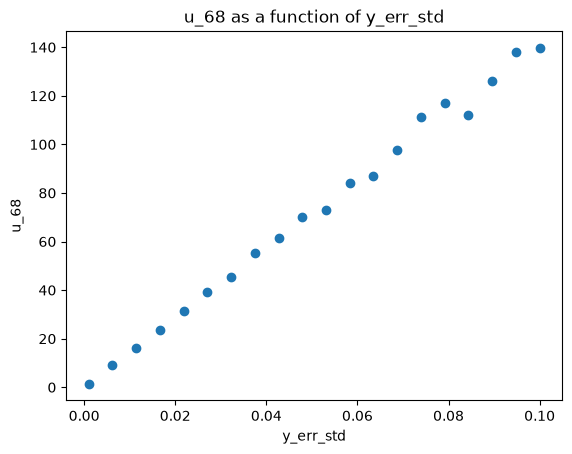

In [9]:
plt.scatter(y_err_std_arr, u_68_arr)
plt.title("u_68 as a function of y_err_std")
plt.xlabel("y_err_std")
plt.ylabel("u_68")
plt.show()

We can see that there seems to be a linear reationship between the uncertainty of our exposure time fit and the standard deviation of the y-values. Now we want to observe the dependence on the number of points.

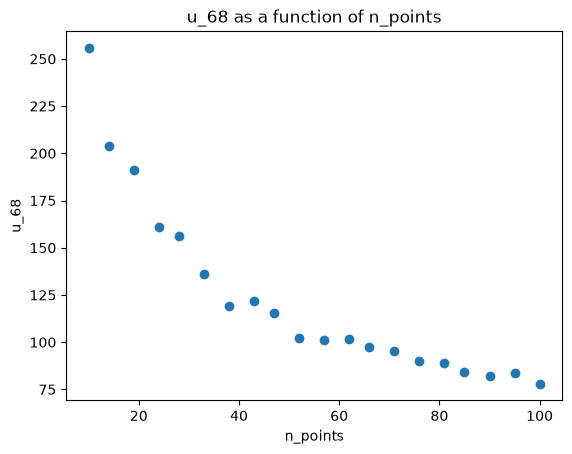

In [11]:
n_points_arr = np.linspace(10, 100, 20, dtype=int)
u_68_arr = np.zeros(n_points_arr.shape)

for i, n_points in enumerate(n_points_arr):
    u_68_arr[i] = get_u_68(1_000, n_points, y_err_std, x_length, order,
        sigma_phi, mu, t_exposure_1)

plt.scatter(n_points_arr, u_68_arr)
plt.title("u_68 as a function of n_points")
plt.xlabel("n_points")
plt.ylabel("u_68")
plt.show()

The relationship is described by

$$
u_{68} \propto \frac{1}{\sqrt n}.
$$

Combined we therefore have

$$
u_{68} \propto \frac{\sigma_y}{\sqrt n}.
$$

This means: If we want to halve the uncertainty of our fitting result, we can either halve the standard deviation of the y-errors or we can quadruple the number of measurement points.